In [1]:
!pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless
!pip install opencv-contrib-python==4.10.0.84

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 60.7 MB/s  0:00:01


In [2]:
import cv2

print("OpenCV Version:", cv2.__version__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))

OpenCV Version: 4.10.0
CascadeClassifier: True


Saving 9KCnHpObInTf5GtUHXvwaByG1SYZt7-zgRSMbq7S9AsyJz1qU1iQ5DCqAL7qcEdJQNTtkoSuJwDiDQ1o3zSCZRJcV3NFRMRI3BuTc9MR99GVe705URUpUZwhvVBlB_go3i3cV4FqtbZs04Nr9hcbTueiDK9KZQIigDYDX2b3jsOLUkJxFdU0hnXszJAN5tfI.jpg to 9KCnHpObInTf5GtUHXvwaByG1SYZt7-zgRSMbq7S9AsyJz1qU1iQ5DCqAL7qcEdJQNTtkoSuJwDiDQ1o3zSCZRJcV3NFRMRI3BuTc9MR99GVe705URUpUZwhvVBlB_go3i3cV4FqtbZs04Nr9hcbTueiDK9KZQIigDYDX2b3jsOLUkJxFdU0hnXszJAN5tfI.jpg
Number of smiles detected: 6


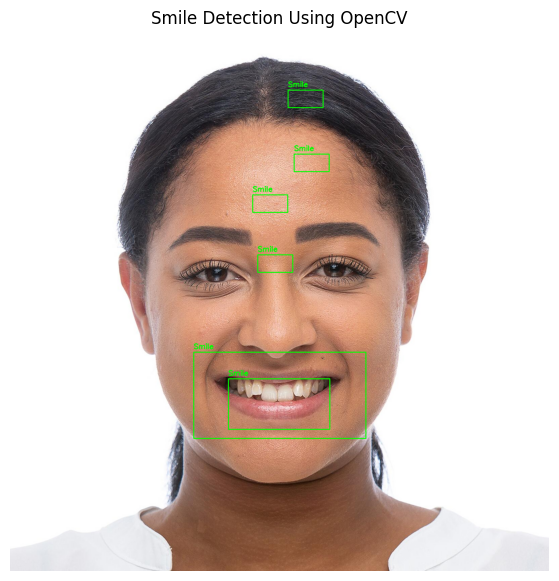

In [3]:

import cv2
import matplotlib.pyplot as plt
from google.colab import files

# Upload image dynamically
uploaded = files.upload()

# Read uploaded image
image_path = list(uploaded.keys())[0]
img = cv2.imread(image_path)

if img is None:
    raise ValueError("Unable to load image!")

# Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Load smile detection classifier
smile_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_smile.xml"
)

if smile_cascade.empty():
    raise IOError("Smile classifier not loaded!")

# Detect smiles
smiles = smile_cascade.detectMultiScale(
    gray,
    scaleFactor=1.7,
    minNeighbors=20,
    minSize=(25, 25)
)

# Draw rectangles around detected smiles
for (x, y, w, h) in smiles:
    cv2.rectangle(
        img, (x, y), (x+w, y+h),
        (0, 255, 0), 2
    )
    cv2.putText(
        img, "Smile", (x, y-10),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7, (0, 255, 0), 2
    )

# Display output
print("Number of smiles detected:", len(smiles))

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Smile Detection Using OpenCV")
plt.axis("off")
plt.show()
